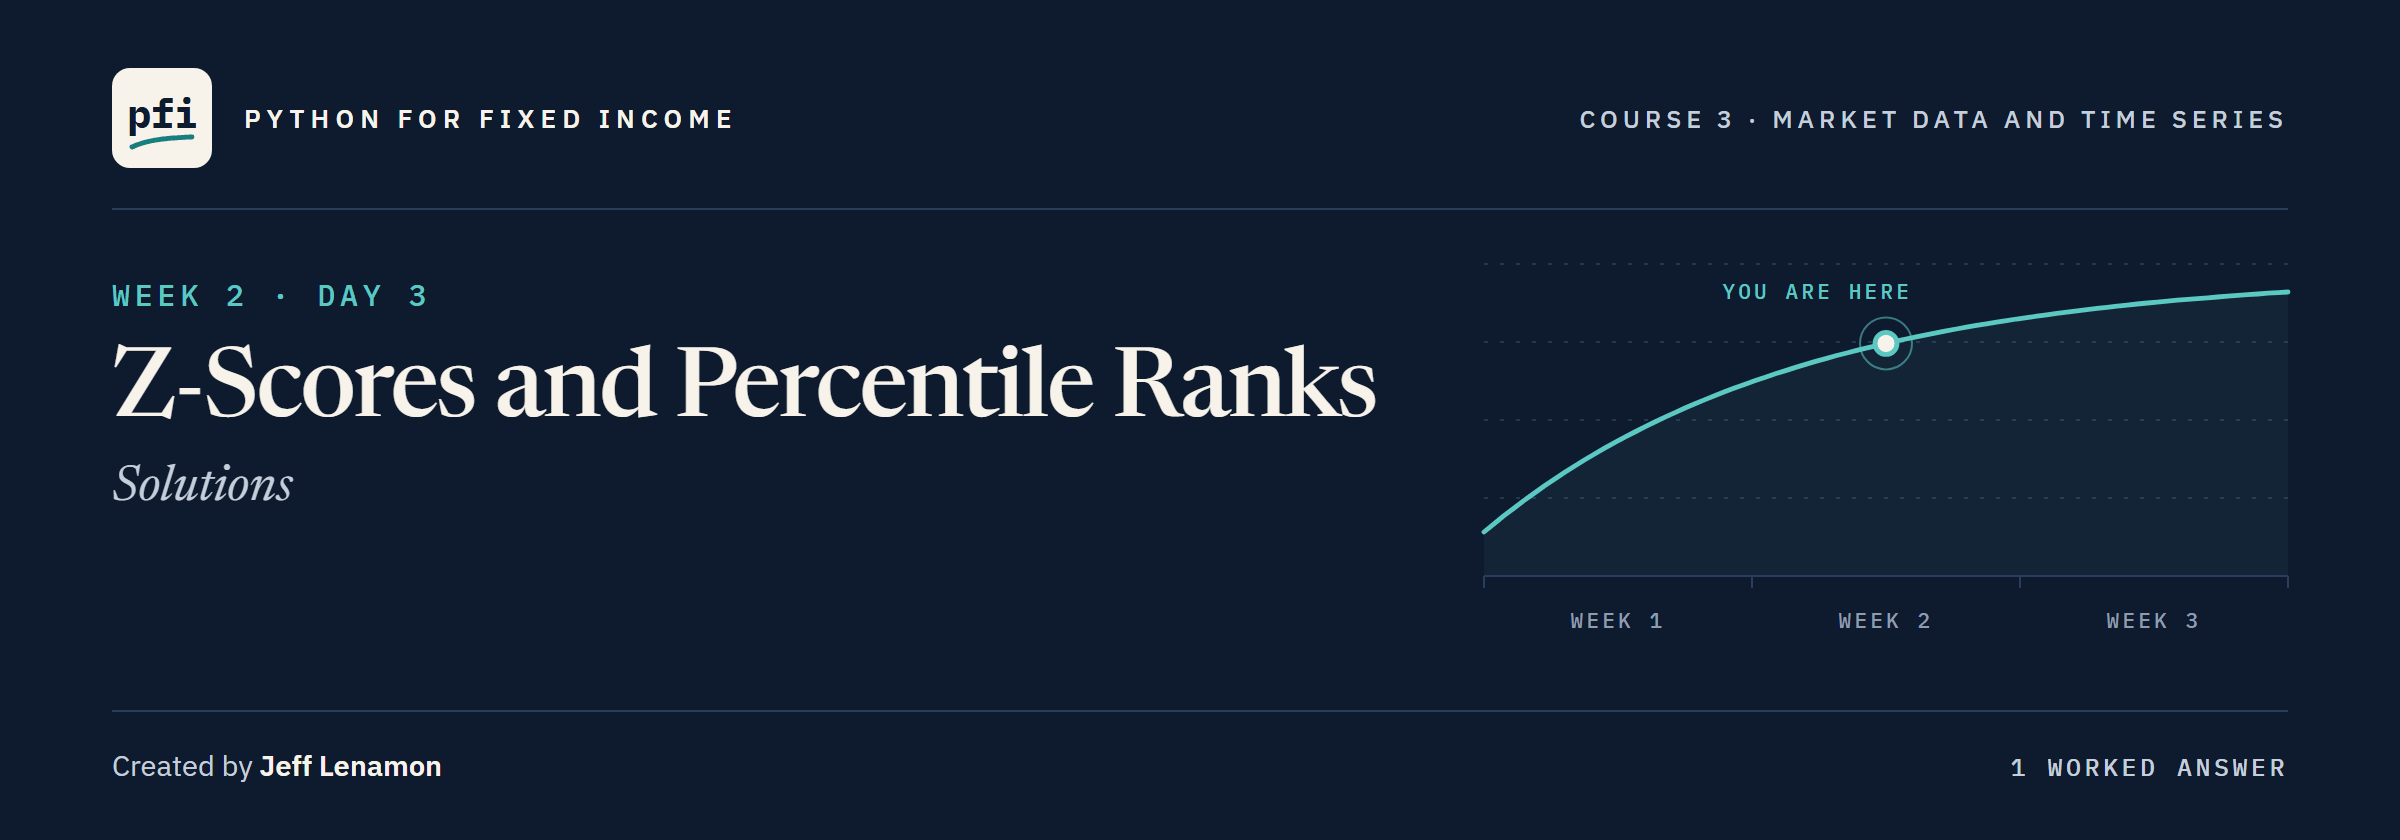

# Z-Scores and Percentile Ranks: Solutions

Week 2, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day3/08_z_scores_and_percentile_ranks_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports and the Treasury file, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 08 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(8, after=8)

Work folder pfi_course3_08_k4w7q2xr: 3 data files, Course 2's bondmath.py, marketdata.py as notebook 08 left it, 8 commits, tagged week1


In [2]:
import importlib

import numpy as np
import pandas as pd

import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
ten_year = treasury['10 Yr']
print(f'{len(treasury):,} market days, the last on {treasury.index[-1]:%Y-%m-%d}')

2,940 market days, the last on 2026-10-02


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
five_year = treasury['5 Yr']
ex1_z = md.rolling_zscore(five_year).iloc[-1]
ex1_pct = md.rolling_percentile_rank(five_year).iloc[-1]
print(f'5 Yr {five_year.iloc[-1]:.2f} percent: z-score {ex1_z:.4f}, percentile rank {ex1_pct:.4f}')

5 Yr 5.06 percent: z-score 2.7960, percentile rank 99.6032


In [5]:
check('Exercise 1 the z-score', ex1_z, 2.7959990869553395)
check('Exercise 1 the percentile rank', ex1_pct, 99.60317460317461)

Exercise 1 the z-score: correct
Exercise 1 the percentile rank: correct


The 5 Yr, like the 10 Yr, sits near the top of its window: 2.80 standard deviations above its mean, 99.6 percent of the window at or below it.

### Exercise 2

In [6]:
slope_5s30s = (treasury['30 Yr'] - treasury['5 Yr']) * 100
ex2_z = md.rolling_zscore(slope_5s30s, window=63).iloc[-1]
ex2_pct = md.rolling_percentile_rank(slope_5s30s, window=63).iloc[-1]
print(f'63 rows: z-score {ex2_z:.4f}, percentile rank {ex2_pct:.4f}')
print(f'252 rows: z-score {md.rolling_zscore(slope_5s30s).iloc[-1]:.4f}, '
      f'percentile rank {md.rolling_percentile_rank(slope_5s30s).iloc[-1]:.4f}')
# the window changes the description: the same level, compared with a shorter history

63 rows: z-score -1.0784, percentile rank 23.8095
252 rows: z-score -2.0664, percentile rank 5.9524


In [7]:
check('Exercise 2 the 63-row z-score', ex2_z, -1.0784129299830423)
check('Exercise 2 the 63-row percentile rank', ex2_pct, 23.809523809523807)

Exercise 2 the 63-row z-score: correct
Exercise 2 the 63-row percentile rank: correct


The same 5s30s, -1.08 over 63 rows and -2.07 over 252: the level did not change, the history it is compared with did.
That is why every description names its window.

### Exercise 3

In [8]:
%%writefile -a marketdata.py


def describe_position(z: float, pct: float) -> str:
    """One sentence that says where a value sits in its own window, from a fixed template.

    Units: z in standard deviations, pct in percent (above 0 up to 100). Convention: the sentence describes
    position only; it never says what comes next or what to do. z is rounded to 2 decimals and pct to 1.
    Raises ValueError if z is NaN or pct is outside above 0 up to 100.
    """
    if math.isnan(z):
        raise ValueError("z is NaN: the window is too short or flat")
    if not 0 < pct <= 100:
        raise ValueError(f"pct must be above 0 and at most 100, not {pct}")
    # the side of the mean, in words
    if round(z, 2) == 0:
        side = "at the mean of its window"
    else:
        side = f"{abs(z):.2f} standard deviations {'above' if z > 0 else 'below'} the mean of its window"
    return f"Today's value is {side}, and {pct:.1f} percent of the window is at or below it."

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


# words that forecast, rank, or advise: none of them may appear in a description
FORECAST_WORDS = {"will", "expect", "should", "cheap", "rich", "stretched", "signal", "revert", "overbought",
                  "oversold", "buy", "sell", "due"}


def test_describe_position_only_describes():
    text = md.describe_position(-0.51, 28.2)
    assert text == ("Today's value is 0.51 standard deviations below the mean of its window, "
                    "and 28.2 percent of the window is at or below it.")
    # each word without its punctuation; & keeps what is in both sets
    words = {word.strip(".,'").lower() for word in text.split()}
    assert not words & FORECAST_WORDS
    with pytest.raises(ValueError):
        md.describe_position(1.0, 0.0)
    with pytest.raises(ValueError):
        md.describe_position(float("nan"), 50.0)

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................                                     [100%]
36 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_text = md.describe_position(-0.51, 28.2)
check('Exercise 3 the sentence', ex3_text,
      "Today's value is 0.51 standard deviations below the mean of its window, "
      "and 28.2 percent of the window is at or below it.")

Exercise 3 the sentence: correct


The word test is a reminder, not a proof: a sentence can forecast without any listed word.
The template is the real protection, because it has no slot for a forecast.

### Exercise 4: AI check

The bug: `series.mean()` and `series.std()` are over the whole series, every row to the end of the file, so the z-score for a past date reads rows after it.
Blanking the first 251 values makes it look rolling, which is what hides the bug.
The fix takes the trailing window's mean and standard deviation, as the docstring says: `rolling_zscore` again.

In [12]:
# written for this course in the style of an AI assistant's answer, now fixed
def zscore_from_assistant(series, window=252):
    """Where each value sits in its own trailing window, in standard deviations from its mean.

    Units: none. Convention: z_t = (x_t - mean) / sample standard deviation, both over the trailing
    window that includes x_t (window rows, min_periods = window, ddof=1). Describes position only.
    """
    # the fix: each trailing window's mean and standard deviation, not the whole series'
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std

In [13]:
# notebook 07's cut dates, imported from the test file
from test_marketdata import CUT_DATES

full = zscore_from_assistant(ten_year)
for cut in CUT_DATES:
    # .equals: the same values on the same dates, every one
    stopped = zscore_from_assistant(ten_year.loc[:cut])
    assert full.loc[:cut].equals(stopped), f'z-scores up to {cut} change when later rows arrive'
print('No lookahead')

No lookahead


In [14]:
ex4_no_lookahead = zscore_from_assistant(ten_year).loc[:'2026-06-30'].equals(
    zscore_from_assistant(ten_year.loc[:'2026-06-30']))
ex4_last_z = zscore_from_assistant(ten_year).iloc[-1]
check('Exercise 4 no lookahead', ex4_no_lookahead, True)
check('Exercise 4 the last z-score', ex4_last_z, 3.075234405273874)

Exercise 4 no lookahead: correct
Exercise 4 the last z-score: correct


[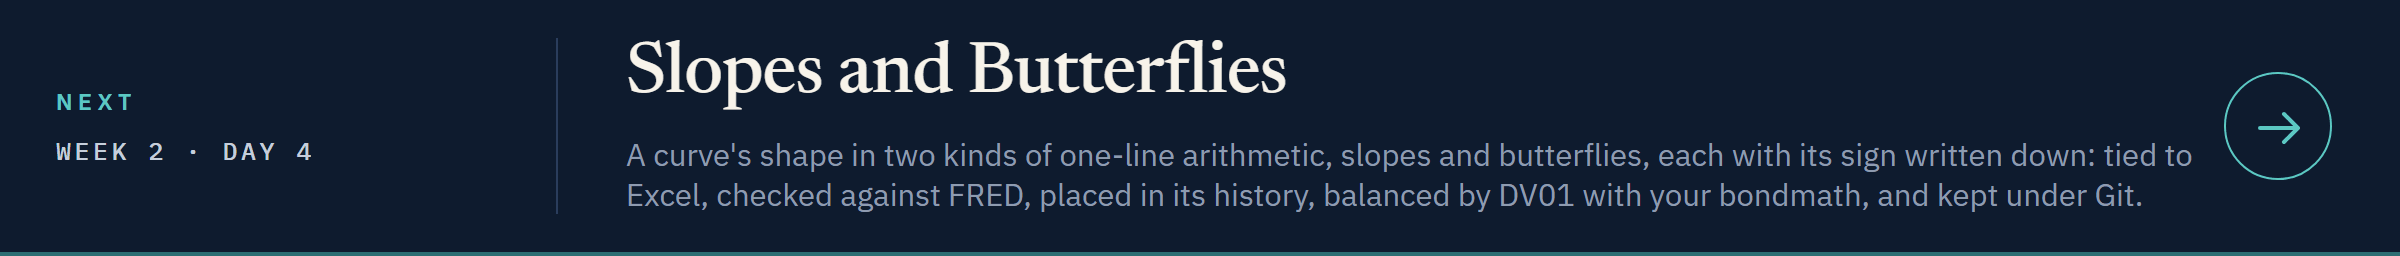](../day4/09_slopes_and_butterflies.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day4/09_slopes_and_butterflies.ipynb)